# Frame 추출과 전처리 (OpenCV)

영상을 VLM에 넣으려면 먼저 **프레임 시퀀스**로 바꿔야 합니다. 이 노트북에서는
OpenCV로 영상 메타데이터를 읽고, 균등 샘플링 / 고정 fps 샘플링 / 장면전환 감지
세 가지 프레임 추출 전략을 비교합니다.

## 사전 준비
```bash
uv sync
ollama pull qwen3-vl:4b
```
실습 영상은 `data/` 폴더에 이미 준비되어 있습니다 (`data/README.md`에 출처/라이선스 정리).

In [1]:
import video_utils as vu

VIDEO = "data/1_scene_cuts_sweeta_commercial_1960s.mp4"

## 영상 메타데이터 확인
샘플링 전략을 정하기 전에 fps·프레임 수·재생 시간·해상도를 먼저 확인합니다.

In [2]:
info = vu.get_video_info(VIDEO)
info

{'fps': 29.97002997002997,
 'frame_count': 1739,
 'duration_sec': 58.024633333333334,
 'width': 640,
 'height': 480}

## 1. 균등 샘플링 (Uniform Sampling)
영상을 N등분해서 각 구간의 가운데 프레임을 뽑습니다. 구현이 간단하고 전체 흐름을
파악하기엔 좋지만, 짧은 이벤트(컷 전환 등)를 정확히 짚어내진 못합니다.

추출된 프레임 수: 8
타임스탬프(초): [3.6, 10.88, 18.12, 25.36, 32.63, 39.87, 47.11, 54.39]


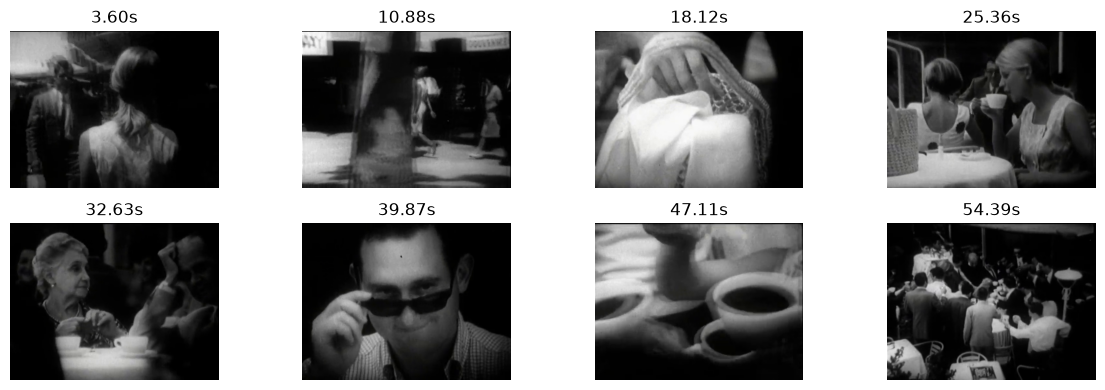

In [3]:
uniform_frames = vu.extract_frames_uniform(VIDEO, n_frames=8)
print("추출된 프레임 수:", len(uniform_frames))
print("타임스탬프(초):", [round(t, 2) for t, _ in uniform_frames])
vu.show_frames(uniform_frames)

## 2. 고정 fps 샘플링
예: 2초에 1장씩. 시간 간격이 균일해 "몇 초 지점"으로 타임스탬프를 매핑하기 쉽습니다.

추출된 프레임 수: 30
타임스탬프(초): [0.0, 2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 14.0, 16.0, 18.0, 20.0, 22.0, 24.0, 26.0, 28.0, 30.0, 32.0, 34.0, 36.0, 38.0, 40.0, 42.0, 44.0, 46.0, 48.0, 50.0, 52.0, 54.0, 56.0, 58.0]


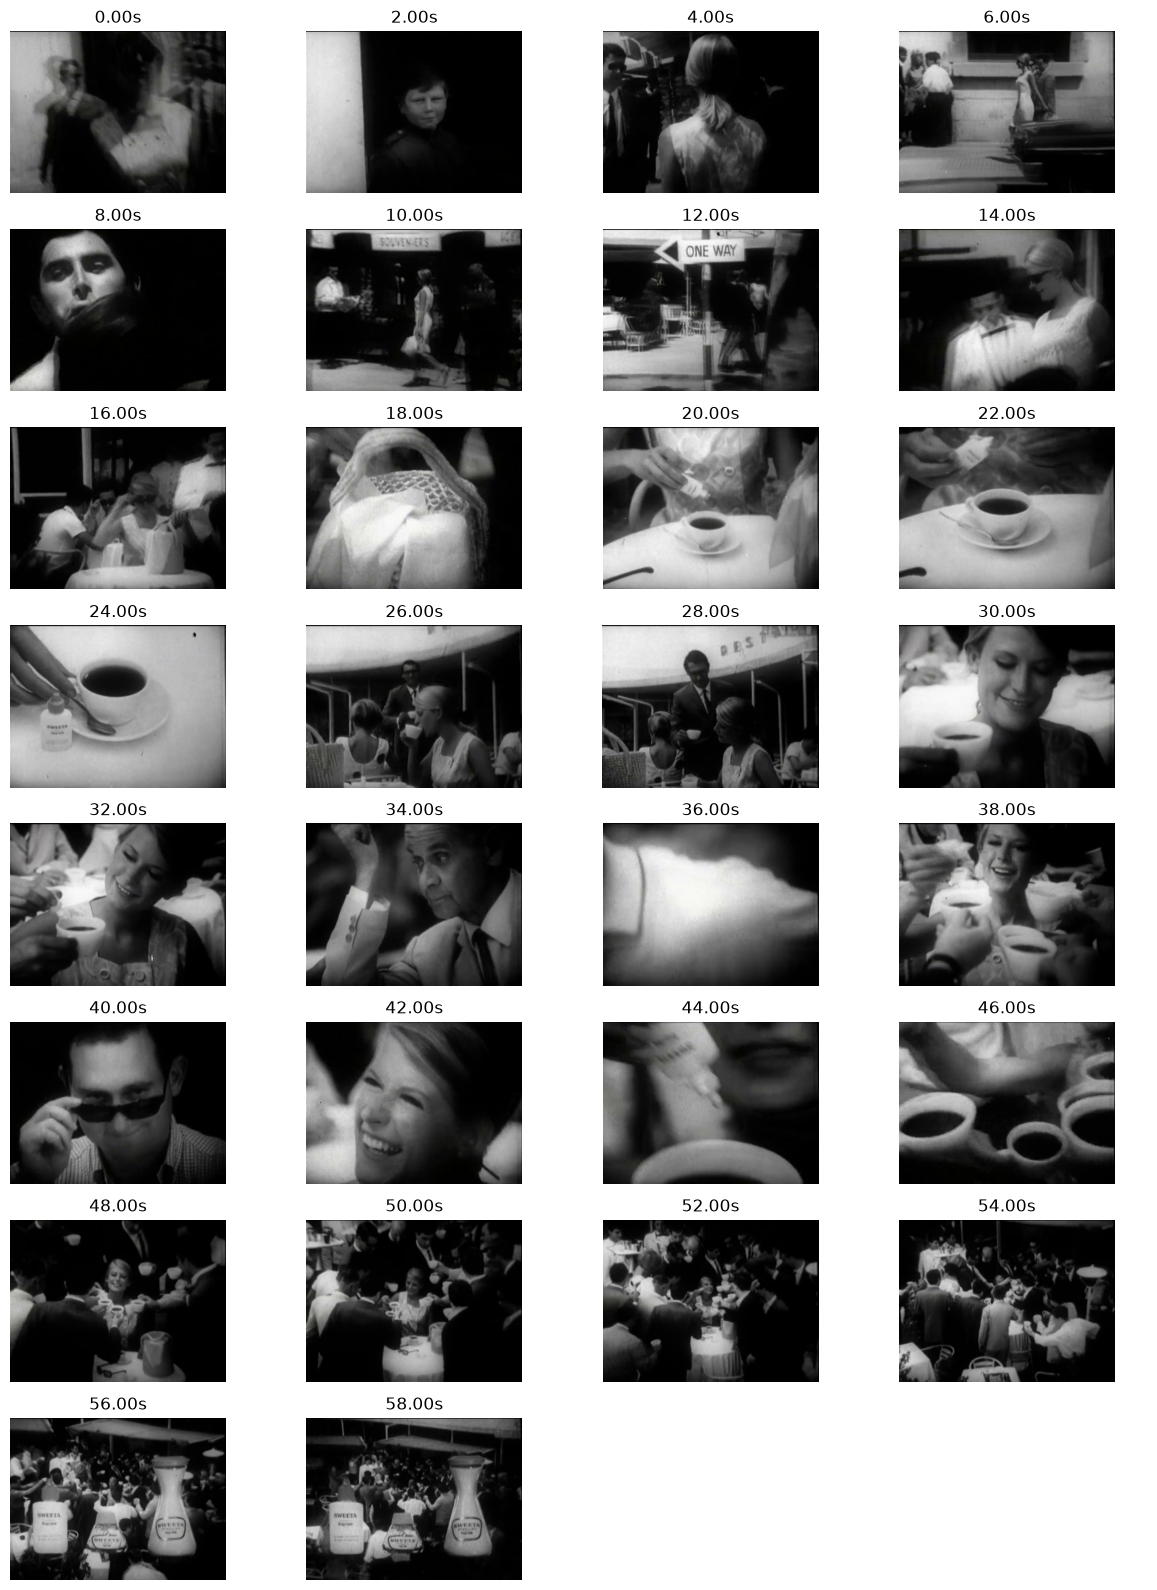

In [4]:
fixed_frames = vu.extract_frames_fixed_fps(VIDEO, sample_fps=0.5)  # 2초당 1장
print("추출된 프레임 수:", len(fixed_frames))
print("타임스탬프(초):", [round(t, 2) for t, _ in fixed_frames])
vu.show_frames(fixed_frames)

## 3. 장면전환 감지 (Scene-change Detection)
직전에 뽑은 프레임과 색상 히스토그램 차이(Chi-Square distance)가 threshold를
넘을 때만 프레임을 뽑습니다. 컷이 바뀌는 지점을 놓치지 않는 대신, 정적인 구간에서는
프레임이 거의 뽑히지 않습니다.

> 이 영상은 사전 분석 결과 실제 컷 전환이 2.3s, 8.6s, 18.0s, 24.9s, 28.1s, 32.2s,
> 39.6s, 43.3s, 44.6s 부근에 있었습니다 (threshold=4.0 기준).

추출된 프레임 수: 10
타임스탬프(초): [0.0, 2.3, 8.61, 17.95, 24.92, 28.06, 32.17, 39.61, 43.34, 44.61]


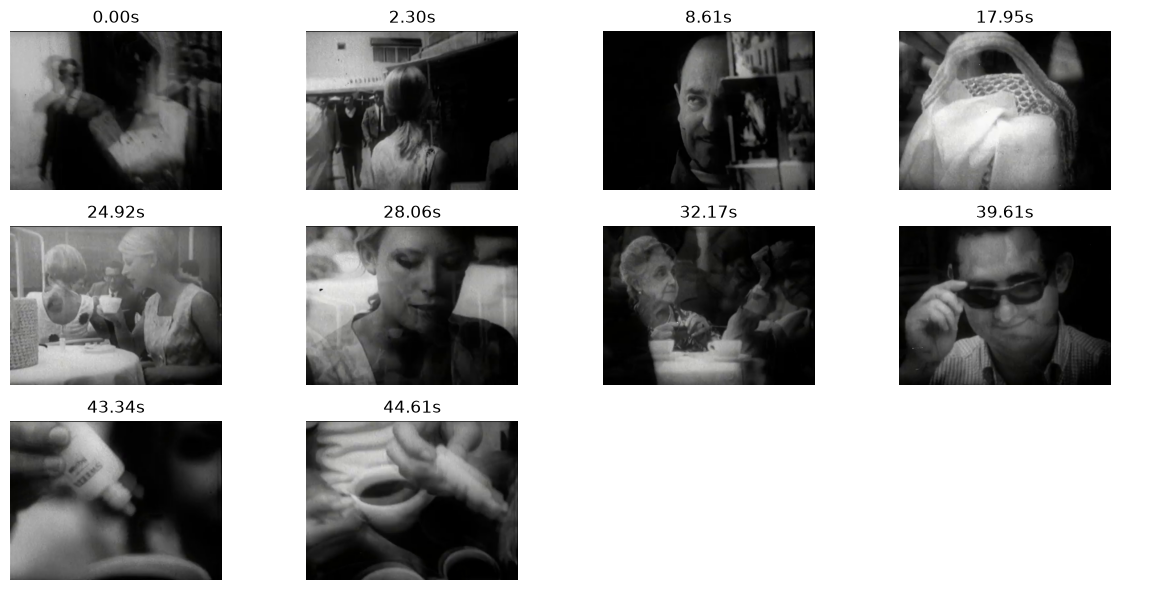

In [5]:
scene_frames = vu.extract_frames_scene_change(VIDEO, threshold=4.0, min_gap_sec=1.0)
print("추출된 프레임 수:", len(scene_frames))
print("타임스탬프(초):", [round(t, 2) for t, _ in scene_frames])
vu.show_frames(scene_frames)

## 세 방식 비교
같은 영상, 비슷한 프레임 수(8~10장)인데도 **어느 시점을 뽑는지**가 다릅니다.
균등/고정fps 샘플링은 시간 축을 기계적으로 나누고, 장면전환 감지는 실제 컷이
바뀌는 지점을 따라갑니다.

In [6]:
print(f"{'전략':<12}{'프레임 수':<10}타임스탬프(초)")
for name, frames in [
    ("균등 샘플링", uniform_frames),
    ("고정 fps", fixed_frames),
    ("장면전환 감지", scene_frames),
]:
    ts = [round(t, 1) for t, _ in frames]
    print(f"{name:<12}{len(frames):<10}{ts}")

전략          프레임 수     타임스탬프(초)
균등 샘플링      8         [3.6, 10.9, 18.1, 25.4, 32.6, 39.9, 47.1, 54.4]
고정 fps      30        [0.0, 2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 14.0, 16.0, 18.0, 20.0, 22.0, 24.0, 26.0, 28.0, 30.0, 32.0, 34.0, 36.0, 38.0, 40.0, 42.0, 44.0, 46.0, 48.0, 50.0, 52.0, 54.0, 56.0, 58.0]
장면전환 감지     10        [0.0, 2.3, 8.6, 18.0, 24.9, 28.1, 32.2, 39.6, 43.3, 44.6]


## 전처리: 프레임 수 = 토큰 비용
프레임을 몇 장 뽑을지가 VLM 호출의 정확도·속도·비용을 좌우합니다. `max_width`로
해상도를 낮춰 한 번 더 비용을 줄일 수 있습니다 (기본값 768px).

In [7]:
small_frames = vu.extract_frames_uniform(VIDEO, n_frames=8, max_width=384)
h, w = small_frames[0][1].shape[:2]
print(f"max_width=384 적용 결과: {w}x{h}")

max_width=384 적용 결과: 384x288


## VLM에 프레임 전달해보기
`ask_video`는 여러 프레임을 한 메시지의 `images` 리스트에 순서대로 담아 전달하고,
프롬프트에 프레임별 타임스탬프를 자동으로 덧붙입니다.

In [8]:
answer = vu.ask_video(
    uniform_frames,
    "아래는 오래된 TV 광고에서 균등한 간격으로 추출한 프레임들이야. "
    "시간 순서대로 어떤 장면들이 이어지는지 3~4문장으로 설명해줘.",
)
print(answer)

3.6초의 프레임에서 여성 모델이 활기찬 실내 공간에 서 있는 캐주얼한 모습으로 광고가 시작됩니다. 10.9초에는 고정


## 정리
- **균등 샘플링**: 구현 간단, 전체 흐름 파악용 기본값
- **고정 fps 샘플링**: 타임스탬프 매핑이 쉬워 이벤트 탐지의 기본값으로 적합
- **장면전환 감지**: 컷이 바뀌는 지점을 놓치지 않지만 임계값(threshold) 튜닝 필요

다음 노트북(`2. 영상 요약과 이벤트 탐지.ipynb`)에서는 이렇게 뽑은 프레임으로
실제 요약·이벤트 탐지 태스크를 수행합니다.